In [2]:
import sys
from pathlib import Path

import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import DataLoader

sys.path.append(
    str(
        Path("..")
        .resolve()
        / "src"
    )
)

from dataset_utils import EuroSATDataset
from model_utils import create_resnet50
from training_utils import train_model

### Seed and device

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        SEED
    )

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    device
)

if device.type == "cuda":

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


### Load data split

In [4]:
train_df = pd.read_csv(
    "../data/splits/train.csv"
)

validation_df = pd.read_csv(
    "../data/splits/validation.csv"
)

test_df = pd.read_csv(
    "../data/splits/test.csv"
)

with open(
    "../data/splits/metadata.json",
    "r"
) as file:

    metadata = json.load(
        file
    )

MEAN = metadata[
    "band_mean"
]

STD = metadata[
    "band_std"
]

print(
    len(train_df),
    len(validation_df),
    len(test_df)
)

print(
    MEAN
)

print(
    STD
)

16200 5400 5400
[1354.4054651331019, 1118.2439995810425, 1042.9298395302856, 947.626202980324, 1199.4728396116657, 1999.7909091374904, 2369.2229256486303, 2296.8260832308547, 732.0834017831307, 12.113278040002893, 1819.0102785463687, 1118.9239114945024, 2594.1408079849057]
[245.71762907843808, 333.00778264154405, 395.0924913916503, 593.7505558886336, 566.4170016995537, 861.1839900603321, 1086.631390746977, 1117.9817079077502, 404.9197888562917, 4.7758446836604795, 1002.5876831066728, 761.3032349896243, 1231.585810422304]


### Create datasets

In [7]:
train_dataset = EuroSATDataset(
    train_df,
    mean=MEAN,
    std=STD,
    image_size=224,
    augment=True
)

validation_dataset = EuroSATDataset(
    validation_df,
    mean=MEAN,
    std=STD,
    image_size=224,
    augment=False
)

test_dataset = EuroSATDataset(
    test_df,
    mean=MEAN,
    std=STD,
    image_size=224,
    augment=False
)

### Create data loaders

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(validation_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

Train batches: 2025
Validation batches: 675
Test batches: 675


### Create baseline model

In [9]:
baseline_model = create_resnet50(
    num_classes=10,
    input_channels=13
)

# Freeze all model parameters first.
for param in baseline_model.parameters():
    param.requires_grad = False

# Allow only the final classification layer to learn.
for param in baseline_model.fc.parameters():
    param.requires_grad = True

baseline_model = baseline_model.to(device)

print("Frozen ResNet-50 baseline")
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in baseline_model.parameters()
        if p.requires_grad
    )
)

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in baseline_model.parameters()
    )
)

Frozen ResNet-50 baseline
Trainable parameters: 20490
Total parameters: 23559882


### Baseline entropy and optimiser

In [10]:
criterion = nn.CrossEntropyLoss()

baseline_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        baseline_model.parameters()
    ),
    lr=1e-4,
    weight_decay=1e-4
)

baseline_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    baseline_optimizer,
    T_max=10
)

### Baseline model training

In [11]:
Path("../models").mkdir(
    parents=True,
    exist_ok=True
)

baseline_model, baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=baseline_optimizer,
    scheduler=baseline_scheduler,
    device=device,
    epochs=10,
    patience=11,
    save_path="../models/resnet50_frozen_best.pth",
    accumulation_steps=1
)

print("Frozen baseline training complete.")

Epoch 01/10 | Train Loss: 1.3830 | Val Loss: 0.8030 | Train Acc: 0.6420 | Val Acc: 0.8228 | Val Macro F1: 0.8134 | 373.4s
Epoch 02/10 | Train Loss: 0.8518 | Val Loss: 0.6114 | Train Acc: 0.7708 | Val Acc: 0.8520 | Val Macro F1: 0.8458 | 346.4s
Epoch 03/10 | Train Loss: 0.7068 | Val Loss: 0.5655 | Train Acc: 0.7948 | Val Acc: 0.8433 | Val Macro F1: 0.8404 | 341.3s
Epoch 04/10 | Train Loss: 0.6349 | Val Loss: 0.4669 | Train Acc: 0.8140 | Val Acc: 0.8726 | Val Macro F1: 0.8675 | 345.6s
Epoch 05/10 | Train Loss: 0.5881 | Val Loss: 0.4851 | Train Acc: 0.8248 | Val Acc: 0.8787 | Val Macro F1: 0.8750 | 346.0s
Epoch 06/10 | Train Loss: 0.5628 | Val Loss: 0.5616 | Train Acc: 0.8288 | Val Acc: 0.8491 | Val Macro F1: 0.8446 | 343.1s
Epoch 07/10 | Train Loss: 0.5472 | Val Loss: 0.4040 | Train Acc: 0.8322 | Val Acc: 0.9002 | Val Macro F1: 0.8971 | 348.1s
Epoch 08/10 | Train Loss: 0.5299 | Val Loss: 0.4246 | Train Acc: 0.8385 | Val Acc: 0.8731 | Val Macro F1: 0.8701 | 341.7s
Epoch 09/10 | Train Loss

### Create model

In [12]:
model = create_resnet50(
    num_classes=10,
    input_channels=13
)

# Ensure all model layers are trainable.
for param in model.parameters():
    param.requires_grad = True

model = model.to(device)

print("Fully trainable ResNet-50")
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

Fully trainable ResNet-50
Trainable parameters: 23559882
Total parameters: 23559882


### Entropy and optimiser

In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

### Training

In [14]:
Path("../models").mkdir(
    parents=True,
    exist_ok=True
)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,
    epochs=10,
    patience=11,
    save_path="../models/resnet50_best.pth",
    accumulation_steps=1
)

print("Full fine-tuning complete.")

Epoch 01/10 | Train Loss: 0.4027 | Val Loss: 0.1259 | Train Acc: 0.8749 | Val Acc: 0.9578 | Val Macro F1: 0.9566 | 416.5s
Epoch 02/10 | Train Loss: 0.1649 | Val Loss: 0.3023 | Train Acc: 0.9454 | Val Acc: 0.9144 | Val Macro F1: 0.9116 | 411.7s
Epoch 03/10 | Train Loss: 0.1185 | Val Loss: 0.0840 | Train Acc: 0.9619 | Val Acc: 0.9717 | Val Macro F1: 0.9708 | 410.2s
Epoch 04/10 | Train Loss: 0.0888 | Val Loss: 0.1229 | Train Acc: 0.9701 | Val Acc: 0.9565 | Val Macro F1: 0.9559 | 409.1s
Epoch 05/10 | Train Loss: 0.0672 | Val Loss: 0.0869 | Train Acc: 0.9768 | Val Acc: 0.9741 | Val Macro F1: 0.9736 | 410.3s
Epoch 06/10 | Train Loss: 0.0511 | Val Loss: 0.0655 | Train Acc: 0.9823 | Val Acc: 0.9830 | Val Macro F1: 0.9823 | 408.7s
Epoch 07/10 | Train Loss: 0.0374 | Val Loss: 0.0544 | Train Acc: 0.9878 | Val Acc: 0.9817 | Val Macro F1: 0.9809 | 410.9s
Epoch 08/10 | Train Loss: 0.0258 | Val Loss: 0.0550 | Train Acc: 0.9915 | Val Acc: 0.9859 | Val Macro F1: 0.9855 | 416.4s
Epoch 09/10 | Train Loss

### Comparison

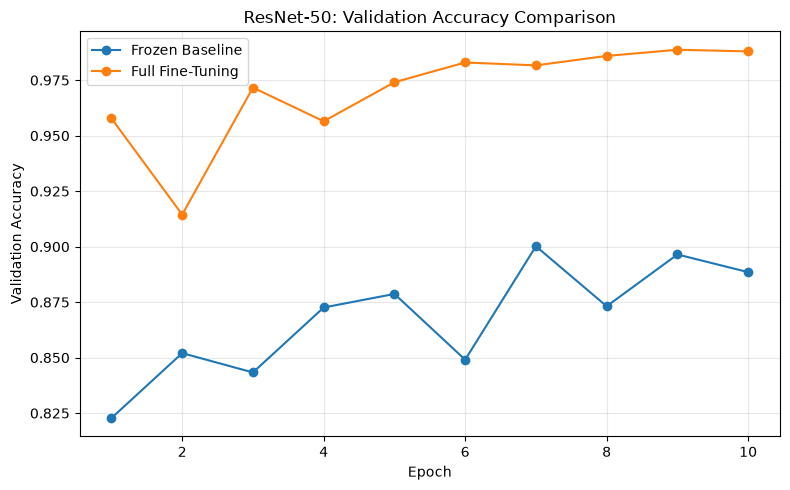

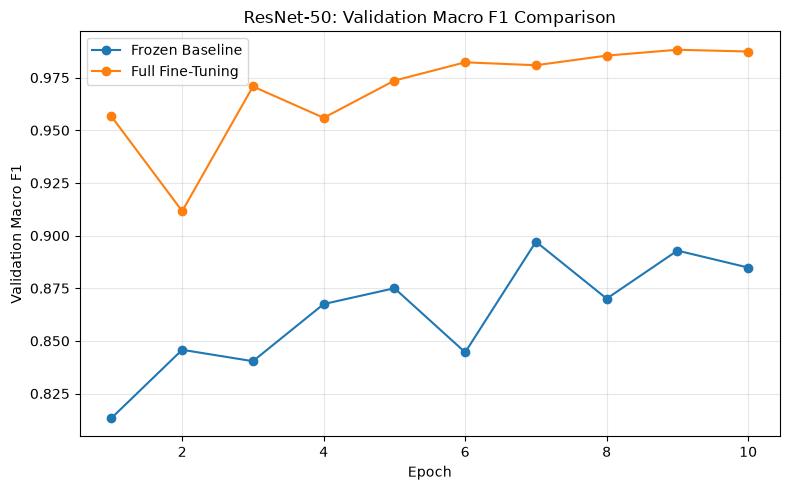

In [15]:
baseline_epochs = range(
    1,
    len(baseline_history["validation_accuracy"]) + 1
)

finetuning_epochs = range(
    1,
    len(history["validation_accuracy"]) + 1
)

# --------------------------------
# Validation Accuracy
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    baseline_epochs,
    baseline_history["validation_accuracy"],
    marker="o",
    label="Frozen Baseline"
)

plt.plot(
    finetuning_epochs,
    history["validation_accuracy"],
    marker="o",
    label="Full Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("ResNet-50: Validation Accuracy Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

Path("../figures").mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    "../figures/resnet50_validation_accuracy_comparison.png",
    dpi=300
)

plt.show()

# --------------------------------
# Validation Macro F1
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(baseline_history["validation_macro_f1"]) + 1),
    baseline_history["validation_macro_f1"],
    marker="o",
    label="Frozen Baseline"
)

plt.plot(
    range(1, len(history["validation_macro_f1"]) + 1),
    history["validation_macro_f1"],
    marker="o",
    label="Full Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("ResNet-50: Validation Macro F1 Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/resnet50_validation_macro_f1_comparison.png",
    dpi=300
)

plt.show()

### Final summary

In [16]:
experiments = {
    "Frozen Baseline": baseline_history,
    "Full Fine-Tuning": history
}

for name, results in experiments.items():

    best_accuracy = max(
        results["validation_accuracy"]
    )

    best_macro_f1 = max(
        results["validation_macro_f1"]
    )

    best_loss = min(
        results["validation_loss"]
    )

    print(f"\n{name}")
    print("-" * len(name))
    print(f"Best validation accuracy: {best_accuracy:.4f}")
    print(f"Best validation macro F1: {best_macro_f1:.4f}")
    print(f"Lowest validation loss:   {best_loss:.4f}")


Frozen Baseline
---------------
Best validation accuracy: 0.9002
Best validation macro F1: 0.8971
Lowest validation loss:   0.3639

Full Fine-Tuning
----------------
Best validation accuracy: 0.9887
Best validation macro F1: 0.9883
Lowest validation loss:   0.0482
